In [ ]:
#Part A: Setup and data
#Mount Drive and unzip:

ZIP_PATH = "/content/drive/MyDrive/SolarguardAiproject/solar.zip"   # change this
!unzip -q "{ZIP_PATH}" -d /content/solar

In [ ]:
#Find your class folders:

import os
for root, dirs, files in os.walk("/content/solar"):
    print(root, "->", len(files), "files,", len(dirs), "subfolders")

/content/solar -> 0 files, 1 subfolders
/content/solar/Faulty_solar_panel -> 0 files, 6 subfolders
/content/solar/Faulty_solar_panel/Bird-drop -> 192 files, 1 subfolders
/content/solar/Faulty_solar_panel/Bird-drop/New -> 16 files, 0 subfolders
/content/solar/Faulty_solar_panel/Dusty -> 191 files, 0 subfolders
/content/solar/Faulty_solar_panel/Physical-Damage -> 70 files, 0 subfolders
/content/solar/Faulty_solar_panel/Snow-Covered -> 124 files, 0 subfolders
/content/solar/Faulty_solar_panel/Clean -> 194 files, 0 subfolders
/content/solar/Faulty_solar_panel/Electrical-damage -> 104 files, 0 subfolders


In [ ]:
#Set the data path and list classes:

from pathlib import Path

DATA_DIR = "/content/solar/Faulty_solar_panel"   # change this
classes = sorted([d.name for d in Path(DATA_DIR).iterdir() if d.is_dir()])
counts = {c: len([p for p in (Path(DATA_DIR)/c).glob("*") if p.suffix.lower() in ['.jpg','.jpeg','.png']]) for c in classes}
print(classes)
print(counts, "TOTAL:", sum(counts.values()))

['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
{'Bird-drop': 191, 'Clean': 193, 'Dusty': 190, 'Electrical-damage': 103, 'Physical-Damage': 69, 'Snow-Covered': 123} TOTAL: 869


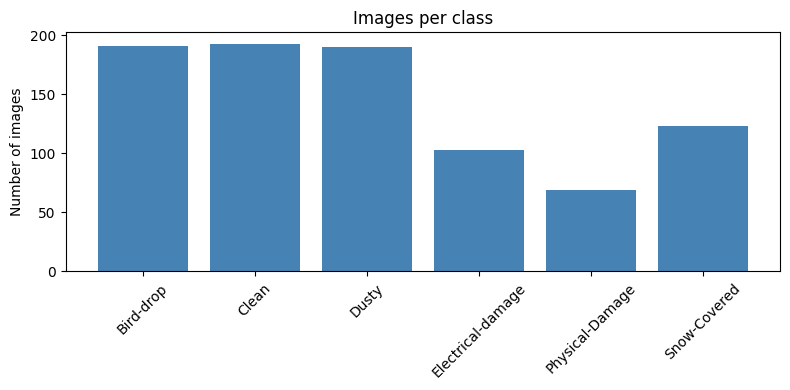

In [ ]:
#Part B:Explore the data : Class distribution chart:

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.xticks(rotation=45); plt.ylabel("Number of images")
plt.title("Images per class"); plt.tight_layout(); plt.show()

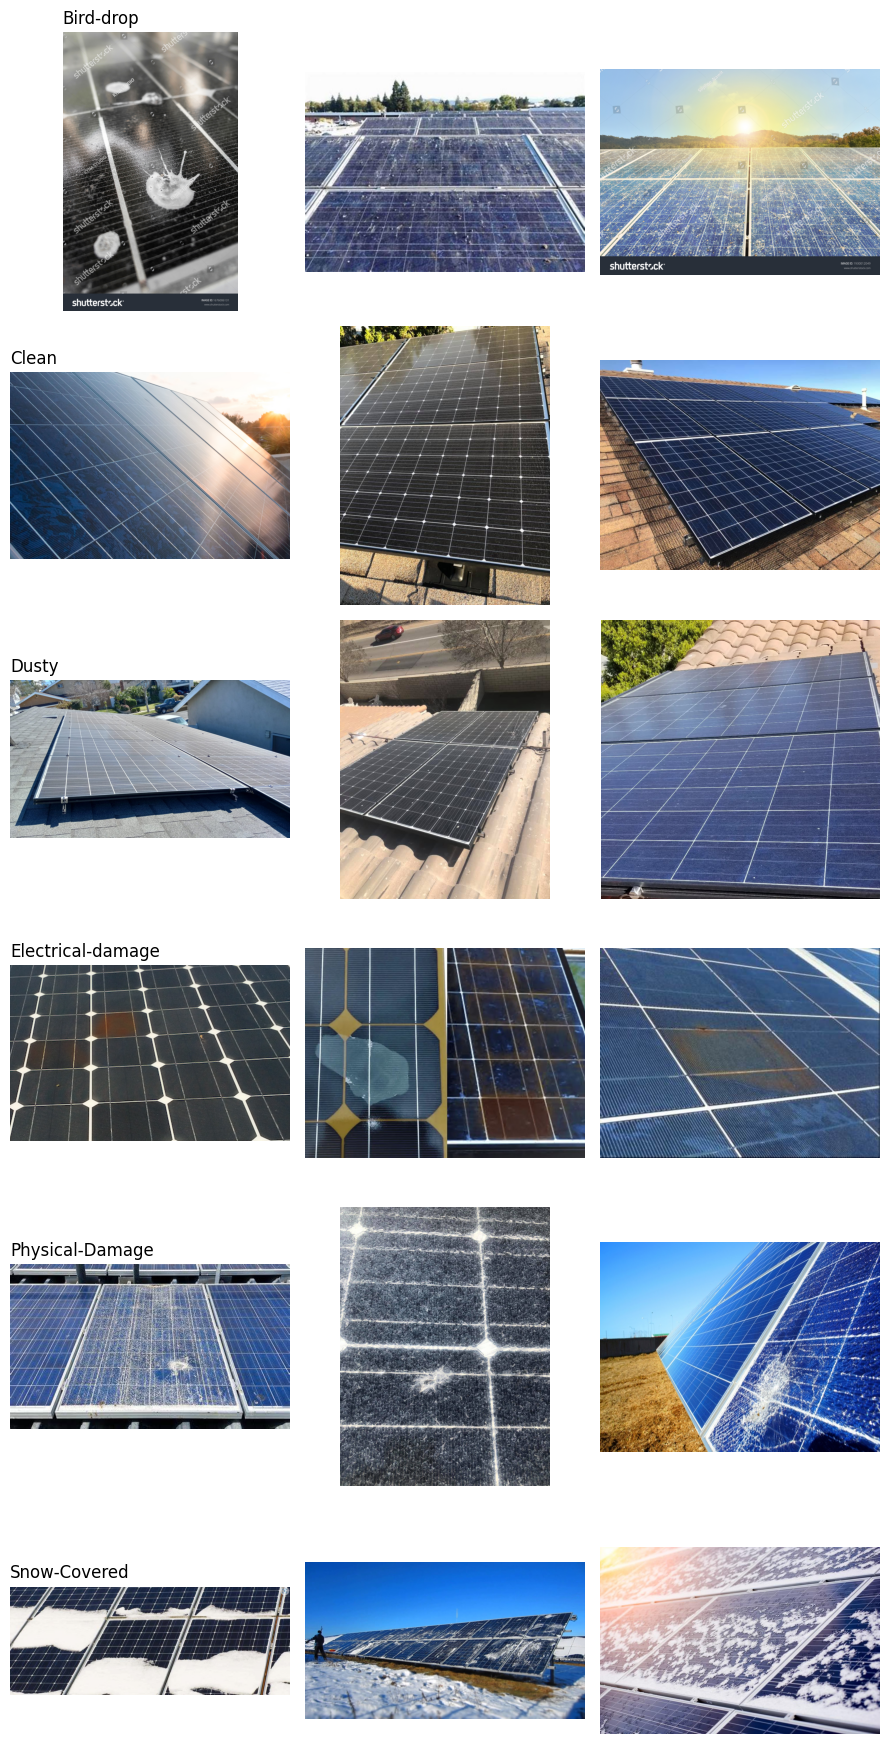

In [ ]:
#Sample Images:

import cv2, random
fig, axes = plt.subplots(len(classes), 3, figsize=(9, 3*len(classes)))
for r, c in enumerate(classes):
    files = [p for p in (Path(DATA_DIR)/c).glob("*") if p.suffix.lower() in ['.jpg','.jpeg','.png']]
    for k, p in enumerate(random.sample(files, min(3, len(files)))):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        axes[r][k].imshow(img); axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(c, loc="left")
plt.tight_layout(); plt.show()

In [ ]:
#Image Sizes:

sizes = []
for c in classes:
    for p in list((Path(DATA_DIR)/c).glob("*"))[:30]:
        img = cv2.imread(str(p))
        if img is not None: sizes.append(img.shape[:2])
print("Different sizes seen:", len(set(sizes)))
print(sizes[:10])

Different sizes seen: 135
[(720, 960), (720, 1280), (632, 474), (355, 474), (459, 816), (742, 503), (578, 474), (675, 900), (2016, 1512), (355, 474)]


In [ ]:
#Part C: Preprocessing: Load, convert and resize all images:

import numpy as np
IMG_SIZE = 224
X, y = [], []
for idx, c in enumerate(classes):
    for p in (Path(DATA_DIR)/c).glob("*"):
        if p.suffix.lower() not in ['.jpg','.jpeg','.png']: continue
        img = cv2.imread(str(p))
        if img is None: continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img); y.append(idx)
X, y = np.array(X), np.array(y)
print(X.shape, y.shape)

(869, 224, 224, 3) (869,)


In [ ]:
#Stratified 70/15/15 split:

from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
print("Train:", X_train.shape[0], "Val:", X_val.shape[0], "Test:", X_test.shape[0])

Train: 608 Val: 130 Test: 131


In [ ]:
#Save to Drive:

os.makedirs("/content/drive/MyDrive/SolarGuard", exist_ok=True)
for name, arr in [("X_train",X_train),("X_val",X_val),("X_test",X_test),
                  ("y_train",y_train),("y_val",y_val),("y_test",y_test)]:
    np.save(f"/content/drive/MyDrive/SolarGuard/{name}.npy", arr)

In [ ]:
#Part D: ML baseline (HOG + color histogram)
#Extract features:

from skimage.feature import hog

def extract_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (128, 128))
    h = hog(gray, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv],[0,1,2],None,[8,8,8],[0,180,0,256,0,256]).flatten()
    hist = hist / (hist.sum() + 1e-7)
    return np.concatenate([h, hist])

F_train = np.array([extract_features(i) for i in X_train])
F_val   = np.array([extract_features(i) for i in X_val])
print(F_train.shape)

(608, 2276)


In [ ]:
#Train and evaluate the ML models:

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

scaler = StandardScaler().fit(F_train)      # fit on TRAIN only
Fs_train, Fs_val = scaler.transform(F_train), scaler.transform(F_val)

models = {
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42), F_train, F_val),
    "SVM": (SVC(kernel='rbf', class_weight='balanced'), Fs_train, Fs_val),
    "KNN": (KNeighborsClassifier(n_neighbors=5), Fs_train, Fs_val),
}
results = {}
for name, (m, Xtr, Xv) in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xv)
    results[name] = (accuracy_score(y_val, pred), f1_score(y_val, pred, average="macro"))
    print("=====", name, "=====")
    print(classification_report(y_val, pred, target_names=classes, zero_division=0))

===== Random Forest =====
                   precision    recall  f1-score   support

        Bird-drop       0.91      0.75      0.82        28
            Clean       0.51      0.86      0.64        29
            Dusty       0.68      0.68      0.68        28
Electrical-damage       0.91      0.62      0.74        16
  Physical-Damage       0.88      0.64      0.74        11
     Snow-Covered       0.73      0.44      0.55        18

         accuracy                           0.69       130
        macro avg       0.77      0.67      0.70       130
     weighted avg       0.74      0.69      0.70       130

===== SVM =====
                   precision    recall  f1-score   support

        Bird-drop       0.59      0.68      0.63        28
            Clean       0.45      0.76      0.56        29
            Dusty       0.61      0.39      0.48        28
Electrical-damage       0.71      0.62      0.67        16
  Physical-Damage       1.00      0.45      0.62        11
     Snow-

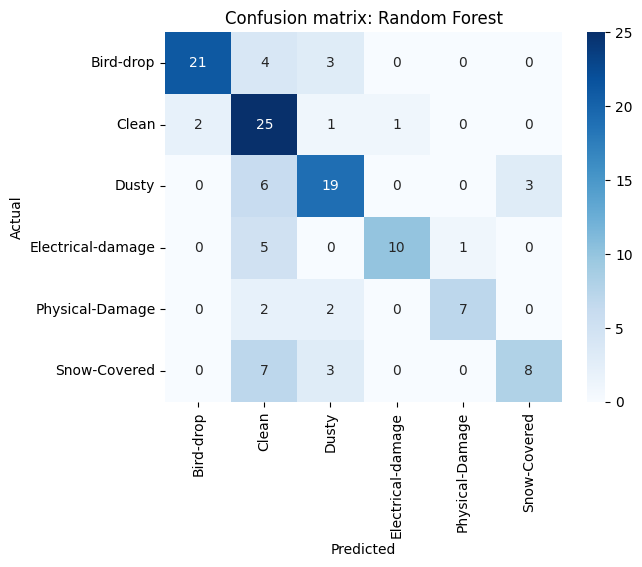

In [ ]:
#Confusion matrix for the best model:

import seaborn as sns
best = max(results, key=lambda k: results[k][1])
m, Xtr, Xv = models[best]
cm = confusion_matrix(y_val, m.predict(Xv))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix: {best}"); plt.show()

In [ ]:
#Part E: DL baseline (CNN from scratch)
#Cell 13: Build and train the CNN:

import tensorflow as tf
from tensorflow.keras import layers, models as kmodels

cnn = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.2072 - loss: 1.9199 - val_accuracy: 0.2385 - val_loss: 1.7005
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.3322 - loss: 1.6016 - val_accuracy: 0.3769 - val_loss: 1.5021
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.4112 - loss: 1.5315 - val_accuracy: 0.3923 - val_loss: 1.4918
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.4276 - loss: 1.4428 - val_accuracy: 0.4308 - val_loss: 1.4223
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.4984 - loss: 1.3489 - val_accuracy: 0.4692 - val_loss: 1.3625
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.5148 - loss: 1.2852 - val_accuracy: 0.5077 - val_loss: 1.2820
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5625 - loss: 1.1860 - val_accuracy: 0.4538 - val_loss: 1.4224
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.5609 - loss: 1.1719 - val_accuracy: 0.5077 - 

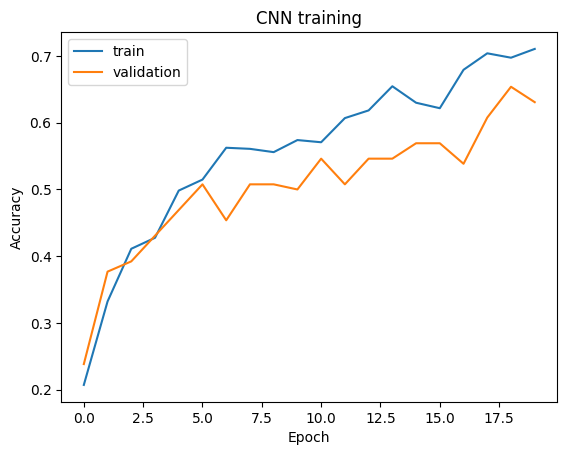

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
                   precision    recall  f1-score   support

        Bird-drop       0.54      0.79      0.64        28
            Clean       0.58      0.72      0.65        29
            Dusty       0.68      0.61      0.64        28
Electrical-damage       0.62      0.31      0.42        16
  Physical-Damage       0.50      0.18      0.27        11
     Snow-Covered       0.94      0.83      0.88        18

         accuracy                           0.63       130
        macro avg       0.64      0.57      0.58       130
     weighted avg       0.64      0.63      0.62       130



In [ ]:
#Learning curves and CNN evaluation:

plt.plot(history.history['accuracy'], label="train")
plt.plot(history.history['val_accuracy'], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("CNN training"); plt.show()

cnn_pred = np.argmax(cnn.predict(X_val), axis=1)
print(classification_report(y_val, cnn_pred, target_names=classes, zero_division=0))
results["CNN (scratch)"] = (accuracy_score(y_val, cnn_pred), f1_score(y_val, cnn_pred, average="macro"))

cnn.save("/content/drive/MyDrive/SolarGuard/cnn_baseline.keras")

In [ ]:
#Part F: Results table and working pipeline
#Cell 15: Comparison table:\

import pandas as pd
df = pd.DataFrame(results, index=["Val Accuracy","Val Macro-F1"]).T.round(3)
print(df)

               Val Accuracy  Val Macro-F1
Random Forest         0.692         0.695
SVM                   0.585         0.595
KNN                   0.338         0.284
CNN (scratch)         0.631         0.582


In [ ]:
#Prediction function (your working pipeline):

def predict_image(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    probs = cnn.predict(img[None, ...], verbose=0)[0]
    return classes[int(np.argmax(probs))], round(float(np.max(probs)), 3)

sample = next((Path(DATA_DIR)/classes[1]).glob("*"))
print("True class:", classes[1], "| Prediction:", predict_image(str(sample)))

True class: Clean | Prediction: ('Clean', 0.965)
